# Question1:

Use feature vectors ( Age, EstimatedSalary) to classify the purchase for the data in purchase_logistic.csv. Do use all required data pre-processing ( scaling (from sklearn.preprocessing import StandardScaler) etc.). Use Gaussian Naive Bayes (from sklearn.naive_bayes import GaussianNB) classifier to predict the result.

Do plot (display) confusion matrix for a better display. Also print the confusion matrix report.



In [16]:
import pandas as pd
df = pd.read_csv('purchase_logistic.csv')
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [2]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [18]:
numeric_cols = []
categorical_cols = []

for col in df.columns:
    if df[col].dtype == 'object':
        categorical_cols.append(col)
    else:
        numeric_cols.append(col)

In [19]:
numeric_cols.remove('User ID')
numeric_cols.remove('Purchased')

In [20]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
df[numeric_cols] = ss.fit_transform(df[numeric_cols])
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,-1.781797,-1.490046,0
1,15810944,Male,-0.253587,-1.460681,0
2,15668575,Female,-1.113206,-0.785290,0
3,15603246,Female,-1.017692,-0.374182,0
4,15804002,Male,-1.781797,0.183751,0
...,...,...,...,...,...
395,15691863,Female,0.797057,-0.844019,1
396,15706071,Male,1.274623,-1.372587,1
397,15654296,Female,1.179110,-1.460681,1
398,15755018,Male,-0.158074,-1.078938,0


In [8]:
categorical_cols

['Gender']

In [21]:
# NOW LETS ENCODE IT OUT
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df[categorical_cols[0]] = le.fit_transform(df[categorical_cols[0]])


df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,1,-1.781797,-1.490046,0
1,15810944,1,-0.253587,-1.460681,0
2,15668575,0,-1.113206,-0.785290,0
3,15603246,0,-1.017692,-0.374182,0
4,15804002,1,-1.781797,0.183751,0
...,...,...,...,...,...
395,15691863,0,0.797057,-0.844019,1
396,15706071,1,1.274623,-1.372587,1
397,15654296,0,1.179110,-1.460681,1
398,15755018,1,-0.158074,-1.078938,0


In [32]:
from sklearn.model_selection import train_test_split

X = df[numeric_cols]
y = df['Purchased']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
X_train

,Age,EstimatedSalary
3,-1.017692,-0.374182
18,0.797057,-1.225763
202,0.128465,1.886912
250,0.606031,-0.902749
274,1.847701,-1.284492
...,...,...
71,-1.304232,-1.255127
106,-1.113206,-1.020209
270,0.510518,1.857547
348,0.128465,0.213115


In [34]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [35]:
gnb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[205.,115.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.64,0.36]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.019e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Age','EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[-0.41,-0.27], [ 0.78, 0.53]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[0.58,0.52], [0.7 ,1.5 ]]"


In [36]:
y_pred = gnb.predict(X_test)
y_pred

array([1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0])

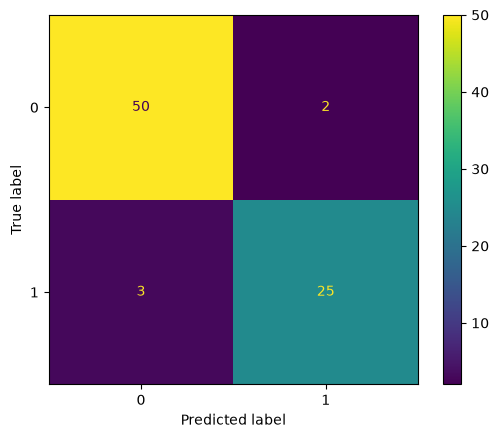

In [37]:
# Do plot (display) confusion matrix for a better display. Also print the confusion matrix report.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

In [38]:
cm

array([[50,  2],
       [ 3, 25]])

In [39]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95        52
           1       0.93      0.89      0.91        28

    accuracy                           0.94        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.94      0.94      0.94        80



In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc_org = accuracy_score(y_test, y_pred)
prec_org = precision_score(y_test, y_pred)
recall_org = recall_score(y_test, y_pred)
f1_org = f1_score(y_test, y_pred)

print("Accuracy:", acc_org, "Precision:", prec_org, "Recall:", recall_org, "F1 Score:", f1_org)

Accuracy: 0.9375 Precision: 0.9259259259259259 Recall: 0.8928571428571429 F1 Score: 0.9090909090909091


# Question2:

Use feature vectors ( Gender ,Age, EstimatedSalary) to classify the purchase for the data in purchase_logistic.csv. Do use all required data pre-processing ( Labelencoding, scaling (from sklearn.preprocessing import StandardScaler) etc.). Use Gaussian Naive Bayes (from sklearn.naive_bayes import GaussianNB) classifier to predict the result.

Do plot (display) confusion matrix for a better display. Also print the confusion matrix report. Also note the difference in accuracy and other metrics.

In [41]:
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,1,-1.781797,-1.490046,0
1,15810944,1,-0.253587,-1.460681,0
2,15668575,0,-1.113206,-0.785290,0
3,15603246,0,-1.017692,-0.374182,0
4,15804002,1,-1.781797,0.183751,0
...,...,...,...,...,...
395,15691863,0,0.797057,-0.844019,1
396,15706071,1,1.274623,-1.372587,1
397,15654296,0,1.179110,-1.460681,1
398,15755018,1,-0.158074,-1.078938,0


In [42]:
from sklearn.model_selection import train_test_split

X = df[numeric_cols + categorical_cols]
y = df['Purchased']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [43]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [44]:
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)
y_pred

array([1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0])

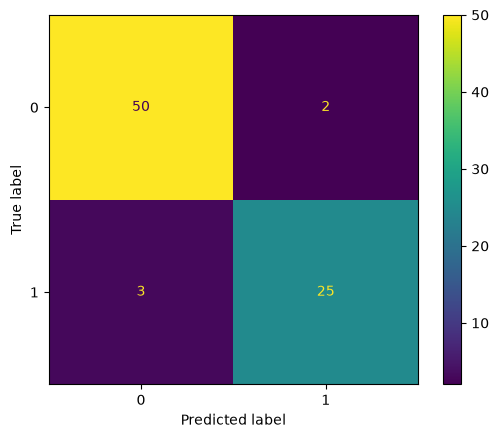

In [45]:
# Do plot (display) confusion matrix for a better display. Also print the confusion matrix report.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

In [46]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95        52
           1       0.93      0.89      0.91        28

    accuracy                           0.94        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.94      0.94      0.94        80



In [47]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc_new = accuracy_score(y_test, y_pred)
prec_new = precision_score(y_test, y_pred)
recall_new = recall_score(y_test, y_pred)
f1_new = f1_score(y_test, y_pred)

print("Accuracy:", acc_new, "Precision:", prec_new, "Recall:", recall_new, "F1 Score:", f1_new)

Accuracy: 0.9375 Precision: 0.9259259259259259 Recall: 0.8928571428571429 F1 Score: 0.9090909090909091


In [48]:
acc_diff = acc_new - acc_org
print("Difference in Accuracy:", acc_diff)



Difference in Accuracy: 0.0


In [ ]:
"""
so we got no diff in vals so gender col was unnecesary
"""

In [49]:
df.corr()

,User ID,Gender,Age,EstimatedSalary,Purchased
User ID,1.000000,-0.025249,-0.000721,0.071097,0.007120
Gender,-0.025249,1.000000,-0.073741,-0.060435,-0.042469
Age,-0.000721,-0.073741,1.000000,0.155238,0.622454
EstimatedSalary,0.071097,-0.060435,0.155238,1.000000,0.362083
Purchased,0.007120,-0.042469,0.622454,0.362083,1.000000
